## Blue Ridge 6LiF run October 2026 deposit SN03

This repeats the work of Run10_26_SN01 on the third deposit, SN03.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from DepositData5 import DepositData

In [2]:
sn03 = DepositData.from_file('Run10_26_SN03.txt', '6LiF on Si')

Using t1
Using t2
Using grading
Using roughness


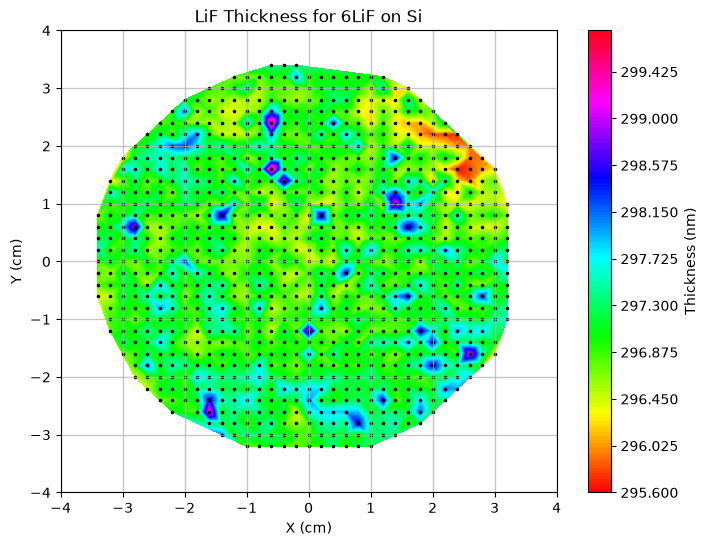

In [3]:
sn03.Ron_plot()

I don't love the low spot in the top left but it is off the active region so it's not really a problem.

In [4]:
zc03 = sn03.t1 + 0.847 * sn03.t2

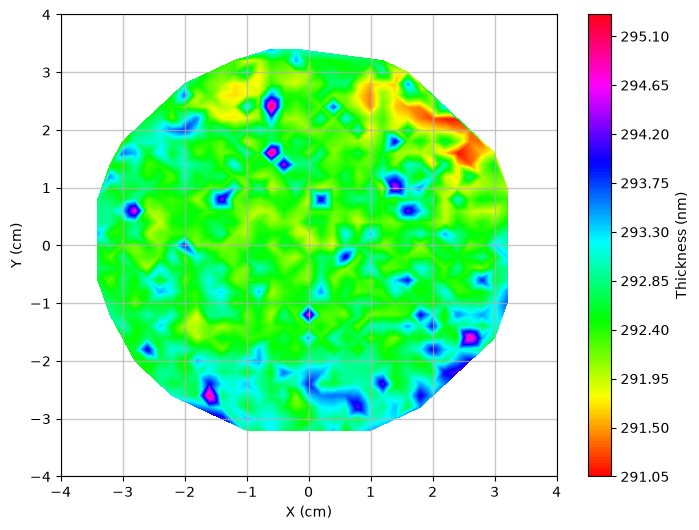

In [5]:
sn03.contour_plot(zc03)

Almost no difference save for the slight decrease in thickness.    

Try for the 3-D anyway.

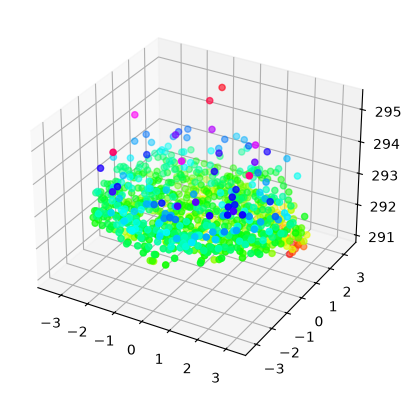

In [6]:
        fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
        surf = ax.scatter(sn03.xdata[sn03.mask], sn03.ydata[sn03.mask], 
                          zc03[sn03.mask], c= zc03[sn03.mask],
                          cmap='hsv')


Again, the data look basically flat but with that clear dip in one spot,right out on the outer edge though. 

Let's try a planar fit. First we have to replace the default zdata with our void corrected data.

In [7]:
sn03.zdata = zc03

In [8]:
# Scaled initial parameters
ipg = [ 5.96,  0.0, 0.0]

def planar_fit(p, a):
    return DepositData.fit_helper(p, a, 'angled_plane')

In [10]:
sn03f =sn03.fit_to(planar_fit, ipg)
print(sn03f)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 228.86286286594006
        x: [ 2.926e+02 -1.274e+02 -1.189e-01]
      nit: 23
      jac: [-5.722e-06 -6.104e-05 -9.346e-05]
 hess_inv: [[ 5.522e-04  1.613e-04 -9.037e-06]
            [ 1.613e-04  1.366e-02 -5.871e-05]
            [-9.037e-06 -5.871e-05  1.937e-04]]
     nfev: 120
     njev: 30


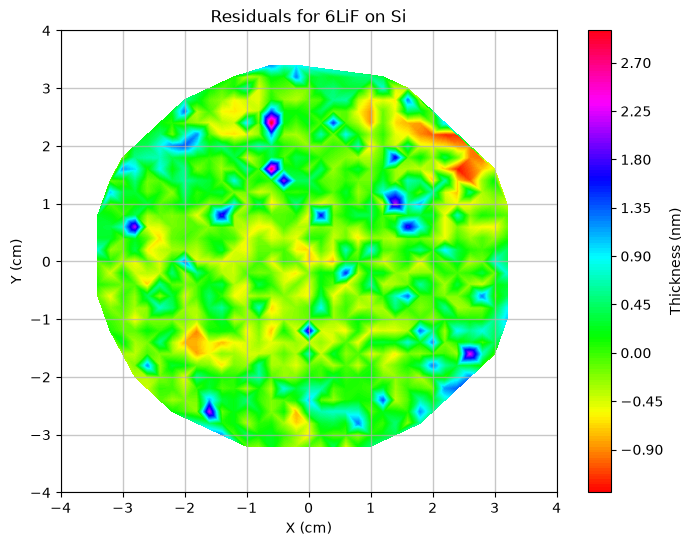

In [11]:
sn03.resid_plot()

Another pretty flat deposit. This one has a bit more slope than the other two. Enough to be worth plotting the fit.

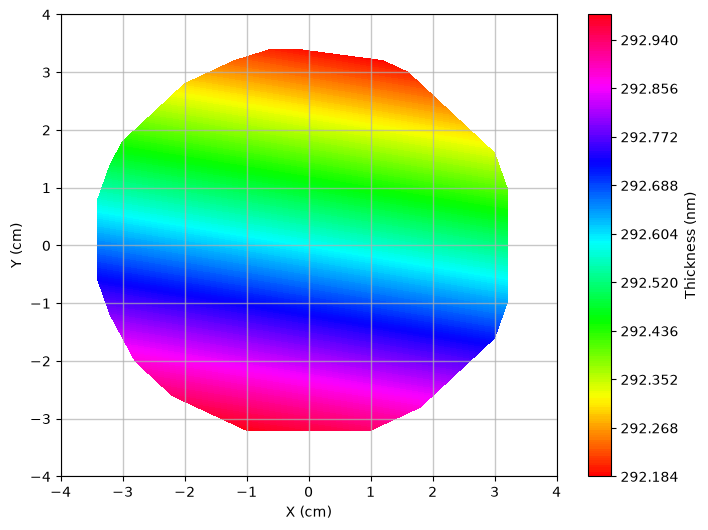

In [12]:
sn03.contour_plot(sn03.fit_z)

So, yes, technically there is a slope, but it is less than 1 nm across the entire wafer. This is another keeper.